# Alignment Search Results Analysis

This notebook analyzes the search results from the alignment optimization process.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set style for better visualization 
plt.rcParams['figure.figsize'] = (12, 6)

# Load the search results
df_first = pd.read_csv('../output/first_search.csv')
df_second = pd.read_csv('../output/second_search.csv')

## First Stage Analysis

The first stage optimizes horizontal shift and BPM scaling.

In [ ]:
# Display first few rows of first stage results
df_first.head()

,vertical_shift,horizontal_shift,scaling_factor,cosine_similarity,binary_cosine_similarity,mse,binary_mse,mae,binary_mae,mean_difference
0,0,0.0,0.900000,0.597190,0.615231,157311.842783,0.461027,335.748289,0.461027,178.765441
1,0,0.0,0.909091,0.635780,0.644634,149636.203979,0.428701,325.498124,0.428701,183.776300
2,0,0.0,0.910000,0.638296,0.645993,149320.638730,0.427492,325.334743,0.427492,184.545802
3,0,0.0,0.917431,0.652273,0.657253,147435.970333,0.416314,323.166665,0.416314,188.696527
4,0,0.0,0.920000,0.654315,0.658272,147431.756094,0.415710,323.165143,0.415710,189.884436


KeyError: 'horizontal_displacement'

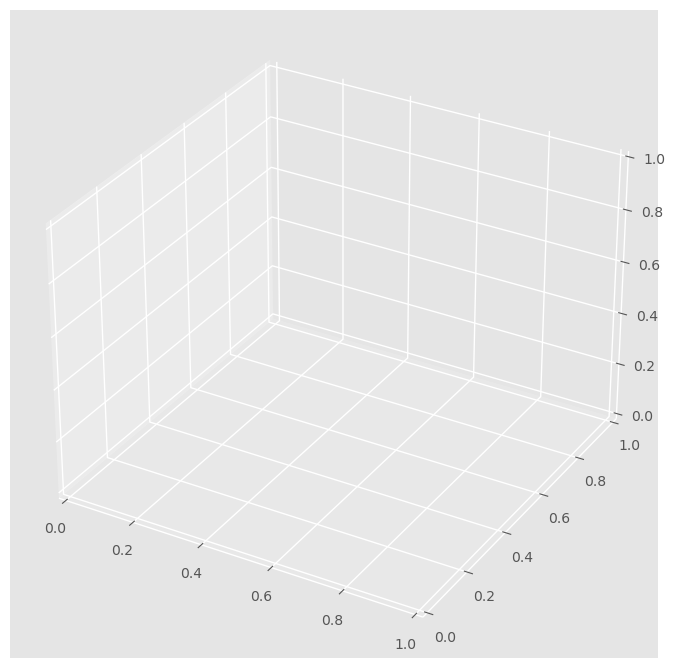

In [ ]:
# Create a 3D plot of the search space
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of search points
sc = ax.scatter(
    df_first['horizontal_shift'],
    df_first['scaling_factor'],
    df_first['cosine_similarity'],
    c=df_first['cosine_similarity'],
    cmap='viridis',
    alpha=0.6
)

ax.set_xlabel('Horizontal Displacement (s)')
ax.set_ylabel('Scaling Factor')
ax.set_zlabel('Cosine Similarity')
ax.set_title('First Stage Search Space - Horizontal Shift & BPM Scaling')

# Add colorbar
cbar = plt.colorbar(sc)
cbar.set_label('Cosine Similarity')

plt.tight_layout()
plt.show()

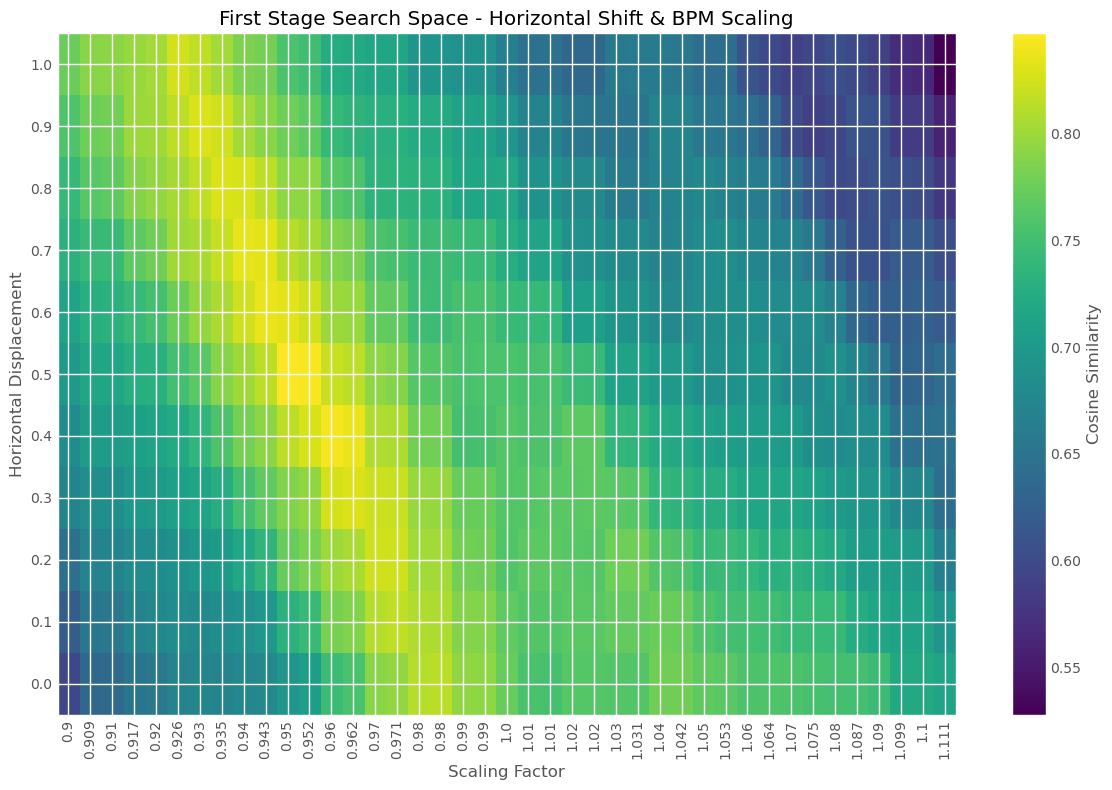

In [ ]:
# Create a heatmap of the search space
plt.figure(figsize=(12, 8))
heatmap_data = df_first.pivot_table(index='horizontal_displacement', columns='scaling_factor', values='cosine_similarity')
plt.imshow(heatmap_data, aspect='auto', origin='lower', cmap='viridis')
plt.colorbar(label='Cosine Similarity')
plt.xlabel("Scaling Factor")
plt.ylabel("Horizontal Displacement")
plt.title('First Stage Search Space - Horizontal Shift & BPM Scaling')
plt.xticks(ticks=np.arange(len(heatmap_data.columns)), labels=np.round(heatmap_data.columns, 3), rotation=90)
plt.yticks(ticks=np.arange(len(heatmap_data.index)), labels=np.round(heatmap_data.index, 1))
plt.tight_layout()
plt.show()



## Second Stage Analysis

The second stage optimizes vertical pitch shift.

In [ ]:
# Display first few rows of second stage results
df_second.head()

,vertical_displacement,horizontal_displacement,scaling_factor,cosine_similarity,binary_cosine_similarity,mse,binary_mse,mae,binary_mae,mean_difference
0,-20.0,0,1.0,0.847117,0.848126,22158.971336,0.186103,113.548413,0.186103,74.200371
1,-19.0,0,1.0,0.847117,0.848126,21132.349983,0.186103,108.502363,0.186103,66.814564
2,-18.0,0,1.0,0.847117,0.848126,20238.840546,0.186103,103.156259,0.186103,58.989575
3,-17.0,0,1.0,0.847117,0.848126,19510.135258,0.186103,97.492259,0.186103,50.699288
4,-16.0,0,1.0,0.847117,0.848126,18982.722649,0.186103,91.500912,0.186103,41.916035


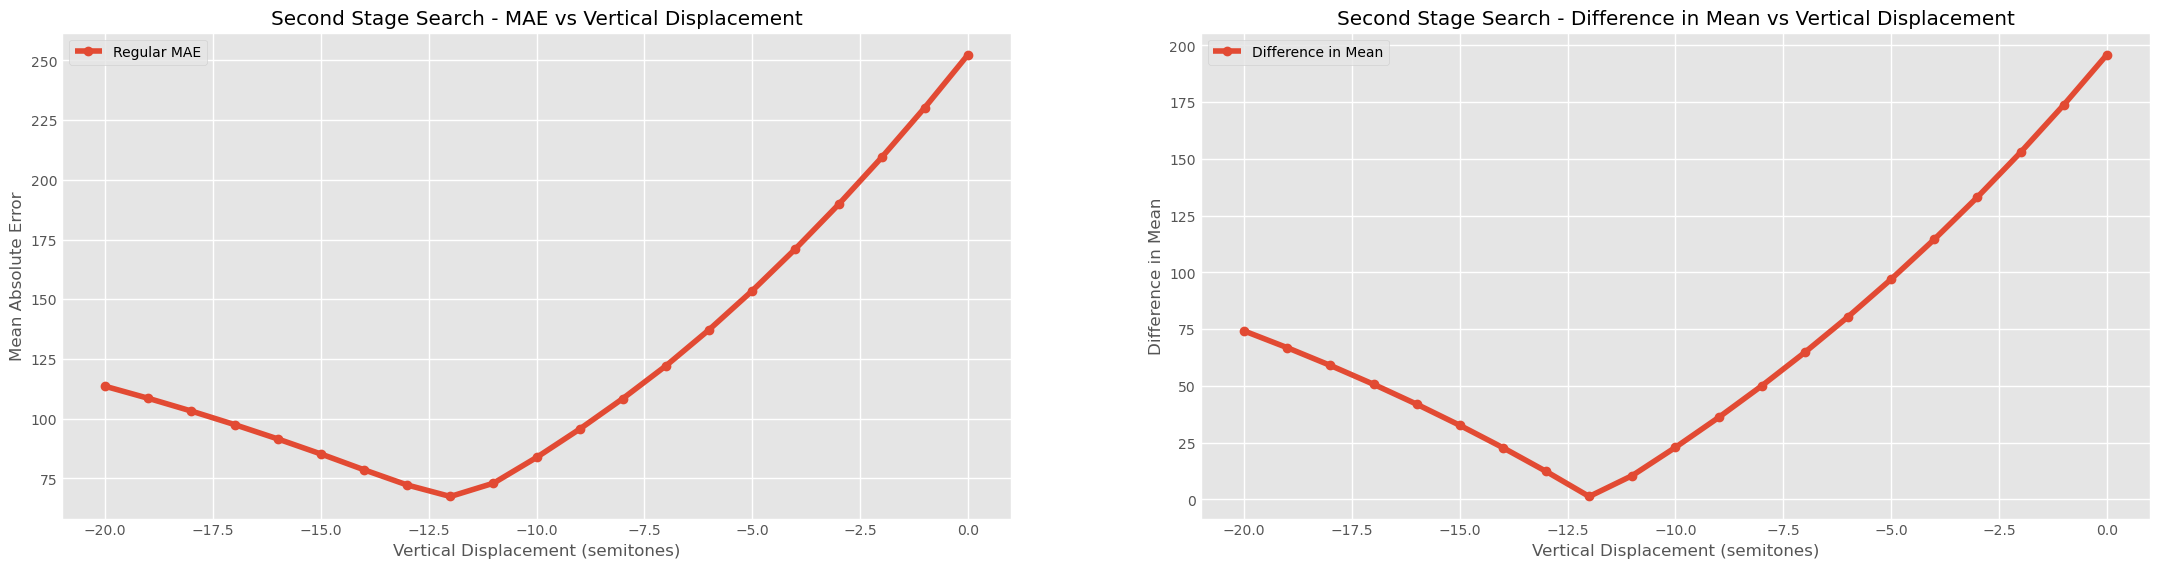

In [ ]:
# Plot MAE and difference in mean vs Vertical Displacement
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 6))

# Plot both regular and binary MAE
ax1.plot(df_second['vertical_displacement'], df_second['mae'], marker='o', label='Regular MAE')
ax1.set_xlabel('Vertical Displacement (semitones)')
ax1.set_ylabel('Mean Absolute Error')
ax1.set_title('Second Stage Search - MAE vs Vertical Displacement')
ax1.legend()
ax1.grid(True)

# Plot difference in mean
ax2.plot(df_second['vertical_displacement'], df_second['mean_difference'], marker='o', label='Difference in Mean')
ax2.set_xlabel('Vertical Displacement (semitones)')
ax2.set_ylabel('Difference in Mean')
ax2.set_title('Second Stage Search - Difference in Mean vs Vertical Displacement')
ax2.legend()
ax2.grid(True)

plt.show()

## Summary of Best Results

In [ ]:
# First stage best result
best_first = df_first.loc[df_first['cosine_similarity'].idxmax()]
print("First Stage Best Parameters:")
print(f"Horizontal Displacement: {best_first['horizontal_displacement']} s")
print(f"Scaling Factor: {best_first['scaling_factor']}")
print(f"Cosine Similarity: {best_first['cosine_similarity']}")

# Second stage best result
best_second = df_second.loc[df_second['mae'].idxmin()]
print("Second Stage Best Parameters:")
print(f"Vertical Displacement: {best_second['vertical_displacement']} semitones")
print(f"MAE: {best_second['mae']}")

First Stage Best Parameters:
Horizontal Displacement: 0.5 s
Scaling Factor: 0.95
Cosine Similarity: 0.8471172264247836
Second Stage Best Parameters:
Vertical Displacement: -12.0 semitones
MAE: 67.387440011037
